In [2]:
import pandas as pd 
import os 
import json
from pandas import json_normalize
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import math
from matplotlib.dates import DayLocator, HourLocator, DateFormatter, drange


main_folder = "D:\\Facultate\\Licenta\\osfstorage-archive\\pmdata"

In [3]:
user_data = pd.read_excel(r'D:\\Facultate\\Licenta\\osfstorage-archive\\pmdata\\participant-overview.xlsx', parse_dates=['Date'], header = 1)

user_data['Gender']=user_data['Gender'].str.strip()

user_data = user_data.drop(columns=['A or B person', 'Max heart rate', 'Date', 'Minutes', 'Seconds', 'Stride walk', 'Stride run'])


user_data.info()

user_data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Participant ID  16 non-null     str  
 1   Age             16 non-null     int64
 2   Height          16 non-null     int64
 3   Gender          16 non-null     str  
dtypes: int64(2), str(2)
memory usage: 764.0 bytes


,Age,Height
count,16.000000,16.000000
mean,34.875000,179.625000
std,11.672618,6.781101
min,23.000000,163.000000
25%,26.000000,177.750000
50%,29.000000,180.000000
75%,42.750000,182.250000
max,60.000000,195.000000


In [4]:
heart_rate = []

for folder in os.listdir(main_folder):
    folder_path = os.path.join(main_folder, folder, 'fitbit', 'heart_rate.json')

    if os.path.exists(folder_path):
            df= pd.read_json(folder_path)
            df['user_id']= folder
            heart_rate.append(df)


hr_df = pd.concat(heart_rate, ignore_index=True)

hr_df['bpm'] = hr_df['value'].apply(lambda x: x.get('bpm') if isinstance(x, dict) else None)

hr_df['dateTime'] = pd.to_datetime(hr_df['dateTime'])
hr_df = hr_df.drop(columns=['value'])


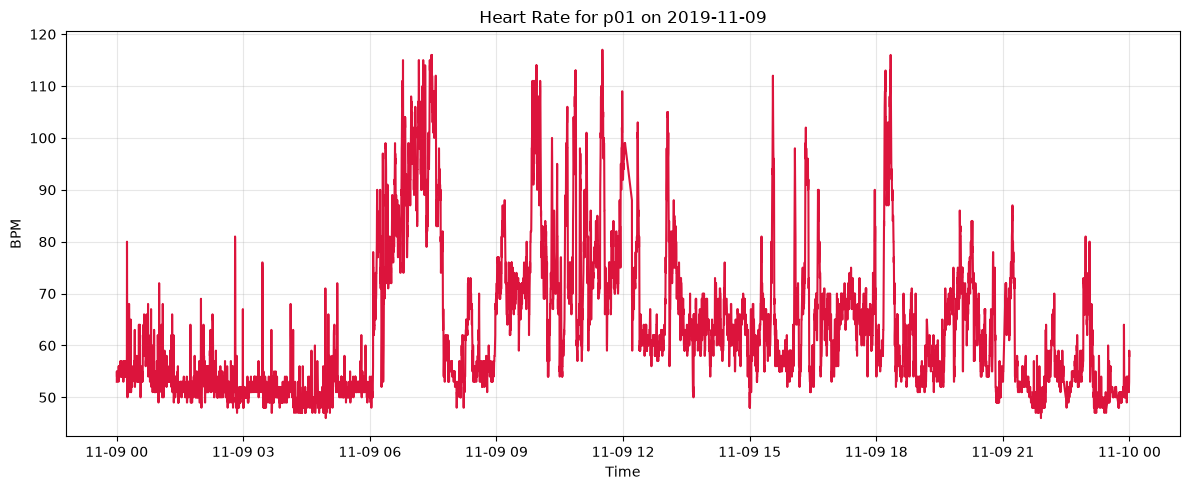

In [5]:
user_id = hr_df['user_id'].unique()[0] 
sample_day = hr_df[(hr_df['user_id'] == user_id) & (hr_df['dateTime'].dt.date == pd.to_datetime('2019-11-09').date())]

plt.figure(figsize=(12, 5))
plt.plot(sample_day['dateTime'], sample_day['bpm'], color='crimson')

plt.title(f'Heart Rate for {user_id} on 2019-11-09')
plt.xlabel('Time')
plt.ylabel('BPM')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
resting_heart_rate = []

for folder in os.listdir(main_folder):
    folder_path = os.path.join(main_folder, folder, 'fitbit', 'resting_heart_rate.json')

    if os.path.exists(folder_path):
            df= pd.read_json(folder_path)
            df['user_id']= folder
            resting_heart_rate.append(df)


resting_hr_df = pd.concat(resting_heart_rate, ignore_index=True)

resting_hr_df['resting_bpm'] = resting_hr_df['value'].apply(lambda x: x.get('value') if isinstance(x, dict) else None)
resting_hr_df['error'] = resting_hr_df['value'].apply(lambda x: x.get('error') if isinstance(x, dict) else None)

resting_hr_df['dateTime'] = pd.to_datetime(resting_hr_df['dateTime'])
resting_hr_df = resting_hr_df.drop(columns=['value'])


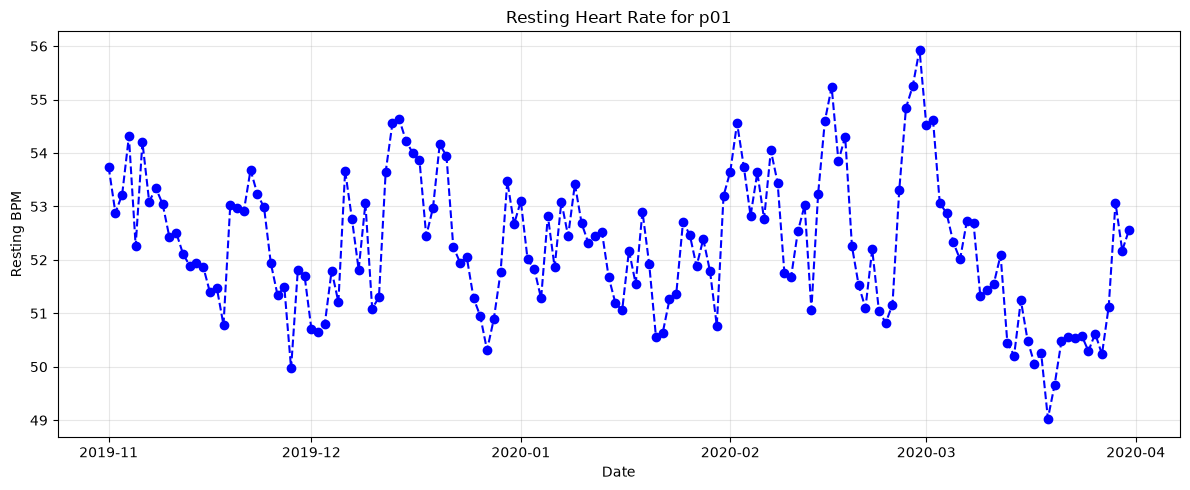

In [7]:
user_id = resting_hr_df['user_id'].unique()[0] 
user_data = resting_hr_df[resting_hr_df['user_id'] == user_id]

plt.figure(figsize=(12, 5))
plt.plot(user_data['dateTime'], user_data['resting_bpm'], color='blue', marker='o', linestyle='--')

plt.title(f'Resting Heart Rate for {user_id}')
plt.xlabel('Date')
plt.ylabel('Resting BPM')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
#Very Active minutes in a day for a person
very_active_minutes = []

for folder in os.listdir(main_folder):
    folder_path = os.path.join(main_folder, folder, 'fitbit', 'very_active_minutes.json')

    if os.path.exists(folder_path):
            df= pd.read_json(folder_path)
            df['user_id']= folder
            very_active_minutes.append(df)


very_active_minutes_df = pd.concat(very_active_minutes, ignore_index=True)

very_active_minutes_df['very_active_minutes'] = pd.to_numeric(very_active_minutes_df['value'].apply(lambda x: x.get('value') if isinstance(x, dict) else x),errors='coerce')

very_active_minutes_df['dateTime'] = pd.to_datetime(very_active_minutes_df['dateTime'])
very_active_minutes_df = very_active_minutes_df.drop(columns=['value'])


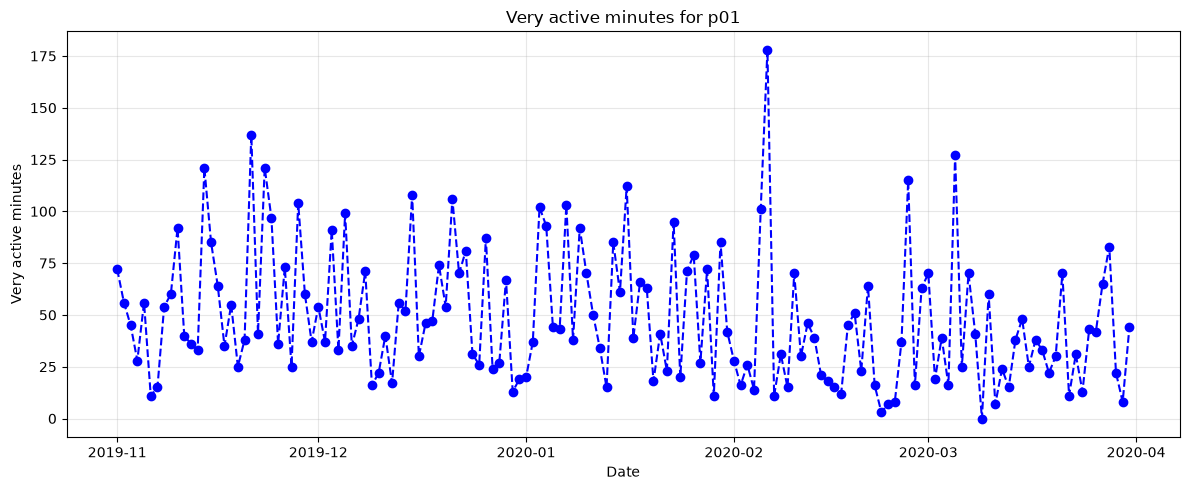

In [9]:
user_id = very_active_minutes_df['user_id'].unique()[0] 
user_data = very_active_minutes_df[very_active_minutes_df['user_id'] == user_id]

plt.figure(figsize=(12, 5))
plt.plot(user_data['dateTime'], user_data['very_active_minutes'], color='blue', marker='o', linestyle='--')

plt.title(f'Very active minutes for {user_id}')
plt.xlabel('Date')
plt.ylabel('Very active minutes')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
#Light Active minutes in a day for a person
lightly_active_minutes = []

for folder in os.listdir(main_folder):
    folder_path = os.path.join(main_folder, folder, 'fitbit', 'lightly_active_minutes.json')

    if os.path.exists(folder_path):
            df= pd.read_json(folder_path)
            df['user_id']= folder
            lightly_active_minutes.append(df)


lightly_active_minutes_df = pd.concat(lightly_active_minutes, ignore_index=True)

lightly_active_minutes_df['lightly_active_minutes'] = pd.to_numeric(lightly_active_minutes_df['value'].apply(lambda x: x.get('value') if isinstance(x, dict) else x),errors='coerce')

lightly_active_minutes_df['dateTime'] = pd.to_datetime(lightly_active_minutes_df['dateTime'])
lightly_active_minutes_df = lightly_active_minutes_df.drop(columns=['value'])


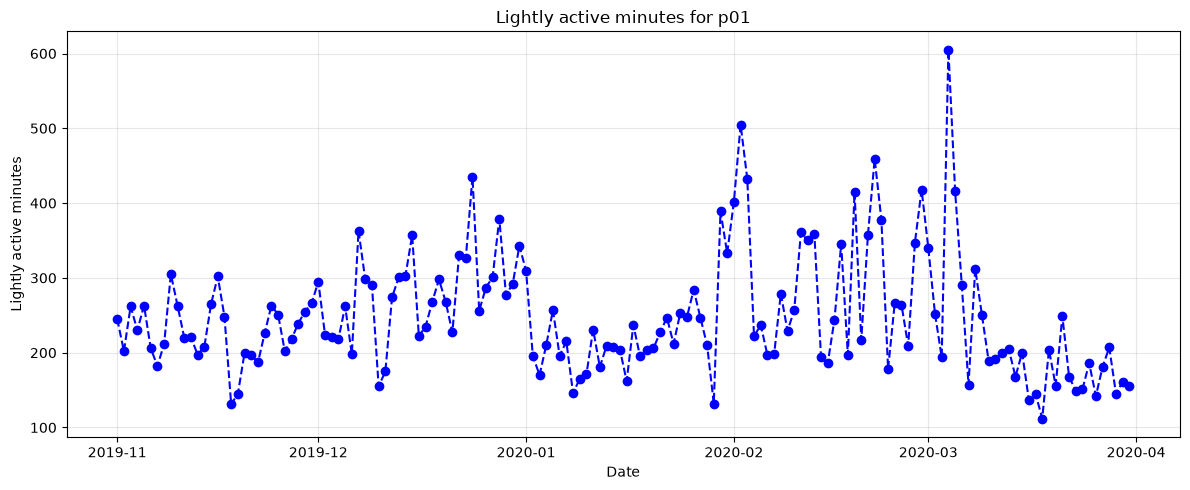

In [11]:
user_id = lightly_active_minutes_df['user_id'].unique()[0] 
user_data = lightly_active_minutes_df[lightly_active_minutes_df['user_id'] == user_id]

plt.figure(figsize=(12, 5))
plt.plot(user_data['dateTime'], user_data['lightly_active_minutes'], color='blue', marker='o', linestyle='--')

plt.title(f'Lightly active minutes for {user_id}')
plt.xlabel('Date')
plt.ylabel('Lightly active minutes')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
#Moderately Active minutes in a day for a person
moderately_active_minutes = []

for folder in os.listdir(main_folder):
    folder_path = os.path.join(main_folder, folder, 'fitbit', 'moderately_active_minutes.json')

    if os.path.exists(folder_path):
            df= pd.read_json(folder_path)
            df['user_id']= folder
            moderately_active_minutes.append(df)


moderately_active_minutes_df = pd.concat(moderately_active_minutes, ignore_index=True)

moderately_active_minutes_df['moderately_active_minutes'] = pd.to_numeric(moderately_active_minutes_df['value'].apply(lambda x: x.get('value') if isinstance(x, dict) else x),errors='coerce')

moderately_active_minutes_df['dateTime'] = pd.to_datetime(moderately_active_minutes_df['dateTime'])
moderately_active_minutes_df = moderately_active_minutes_df.drop(columns=['value'])


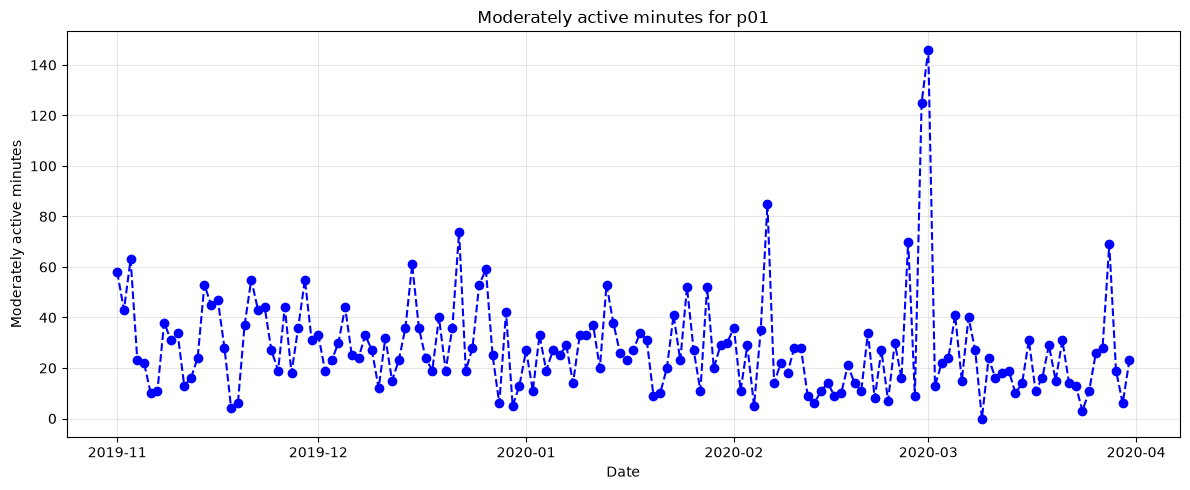

In [13]:
user_id = moderately_active_minutes_df['user_id'].unique()[0] 
user_data = moderately_active_minutes_df[moderately_active_minutes_df['user_id'] == user_id]

plt.figure(figsize=(12, 5))
plt.plot(user_data['dateTime'], user_data['moderately_active_minutes'], color='blue', marker='o', linestyle='--')

plt.title(f'Moderately active minutes for {user_id}')
plt.xlabel('Date')
plt.ylabel('Moderately active minutes')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
#Sedentary minutes in a day for a person
sedentary_minutes = []

for folder in os.listdir(main_folder):
    folder_path = os.path.join(main_folder, folder, 'fitbit', 'sedentary_minutes.json')

    if os.path.exists(folder_path):
            df= pd.read_json(folder_path)
            df['user_id']= folder
            sedentary_minutes.append(df)


sedentary_minutes_df = pd.concat(sedentary_minutes, ignore_index=True)

sedentary_minutes_df['sedentary_minutes'] = pd.to_numeric(sedentary_minutes_df['value'].apply(lambda x: x.get('value') if isinstance(x, dict) else x),errors='coerce')

sedentary_minutes_df['dateTime'] = pd.to_datetime(sedentary_minutes_df['dateTime'])
sedentary_minutes_df = sedentary_minutes_df.drop(columns=['value'])


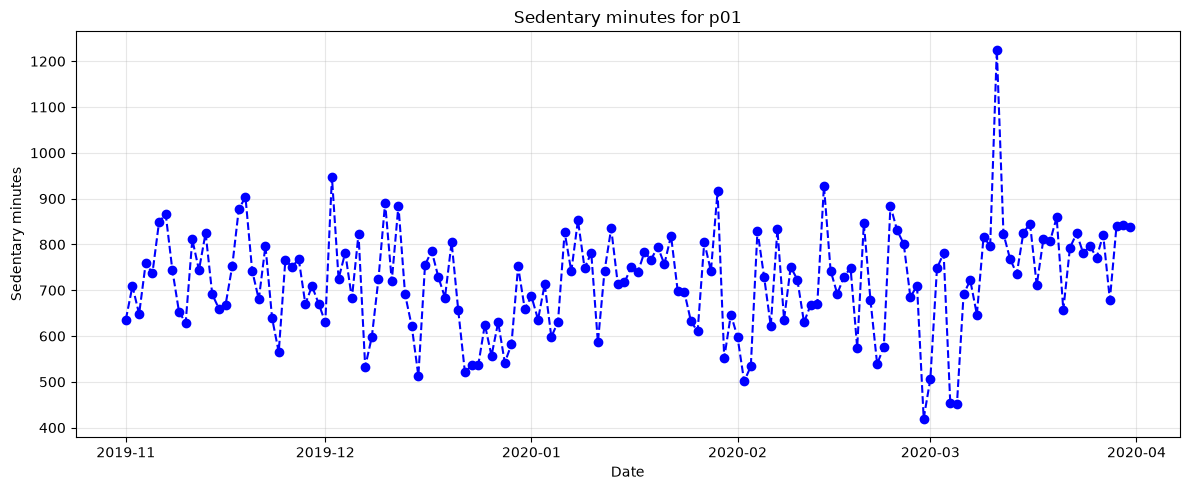

In [15]:
user_id = sedentary_minutes_df['user_id'].unique()[0] 
user_data = sedentary_minutes_df[sedentary_minutes_df['user_id'] == user_id]

plt.figure(figsize=(12, 5))
plt.plot(user_data['dateTime'], user_data['sedentary_minutes'], color='blue', marker='o', linestyle='--')

plt.title(f'Sedentary minutes for {user_id}')
plt.xlabel('Date')
plt.ylabel('Sedentary minutes')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
#Steps for a person
steps = []

for folder in os.listdir(main_folder):
    folder_path = os.path.join(main_folder, folder, 'fitbit', 'steps.json')

    if os.path.exists(folder_path):
            df= pd.read_json(folder_path)
            df['user_id']= folder
            steps.append(df)


steps_df = pd.concat(steps, ignore_index=True)

steps_df['steps'] = pd.to_numeric(steps_df['value'].apply(lambda x: x.get('value') if isinstance(x, dict) else x),errors='coerce')

steps_df['dateTime'] = pd.to_datetime(steps_df['dateTime'])
steps_df = steps_df.drop(columns=['value'])


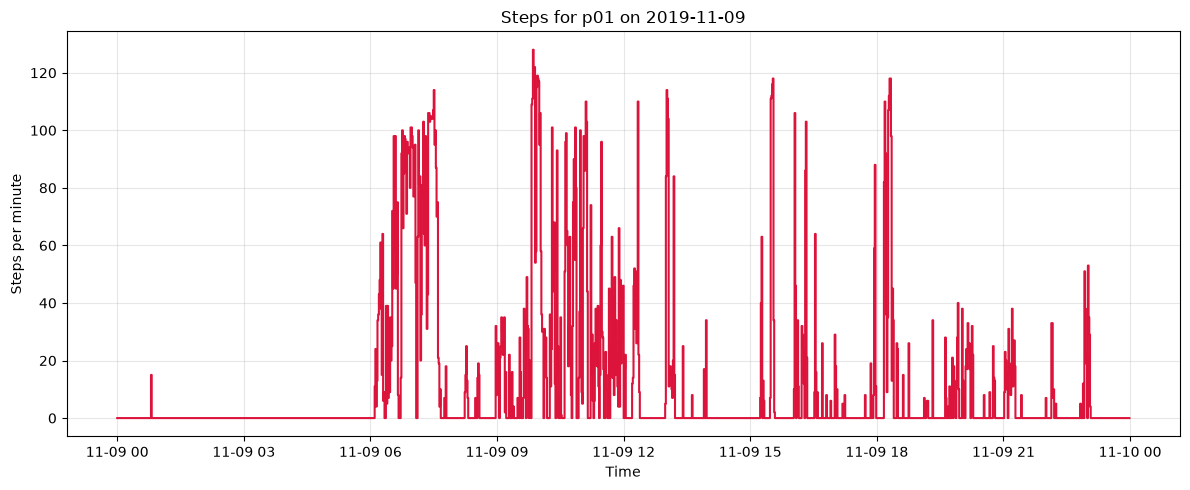

In [17]:
user_id = steps_df['user_id'].unique()[0] 
sample_day = steps_df[(steps_df['user_id'] == user_id) & (steps_df['dateTime'].dt.date == pd.to_datetime('2019-11-09').date())]

plt.figure(figsize=(12, 5))
plt.plot(sample_day['dateTime'], sample_day['steps'], color='crimson', drawstyle='steps-post')

plt.title(f'Steps for {user_id} on 2019-11-09')
plt.xlabel('Time')
plt.ylabel('Steps per minute')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
#Sleep for a person
sleep = []

for folder in os.listdir(main_folder):
    folder_path = os.path.join(main_folder, folder, 'fitbit', 'sleep.json')

    if os.path.exists(folder_path):
            df= pd.read_json(folder_path)
            df['user_id']= folder
            sleep.append(df)


sleep_df = pd.concat(sleep, ignore_index=True)

flattened_sleep = json_normalize(sleep_df['levels'])

# Extract the relevant columns
df = flattened_sleep[['summary.deep.minutes', 'summary.wake.minutes','summary.light.minutes','summary.rem.minutes']]

# Rename the columns for clarity
df.columns = ['deepMinutes', 'wakeMinutes','lightMinutes','remMinutes']

# Concatenate the result back to the original DataFrame
sleeping = pd.concat([sleep_df, df], axis=1)

#Calculating duration in hours

sleeping['duration[hr]'] = sleeping['duration']/ 3600000

# round the numbers to the nearest integer

sleeping['duration[hr]'] = sleeping['duration[hr]'].astype(int)

#Calculating duration in hours

sleeping['timeInBed[hr]'] = sleeping['timeInBed']/ 60

# round the numbers to the nearest integer

sleeping['timeInBed[hr]'] = sleeping['timeInBed[hr]'].astype(int)

#Changing dateOfSleep from object to datetime

sleeping['dateOfSleep'] = pd.to_datetime(sleeping['dateOfSleep'])


# Dropping JSON column

sleeping = sleeping.drop(['levels'], axis=1)



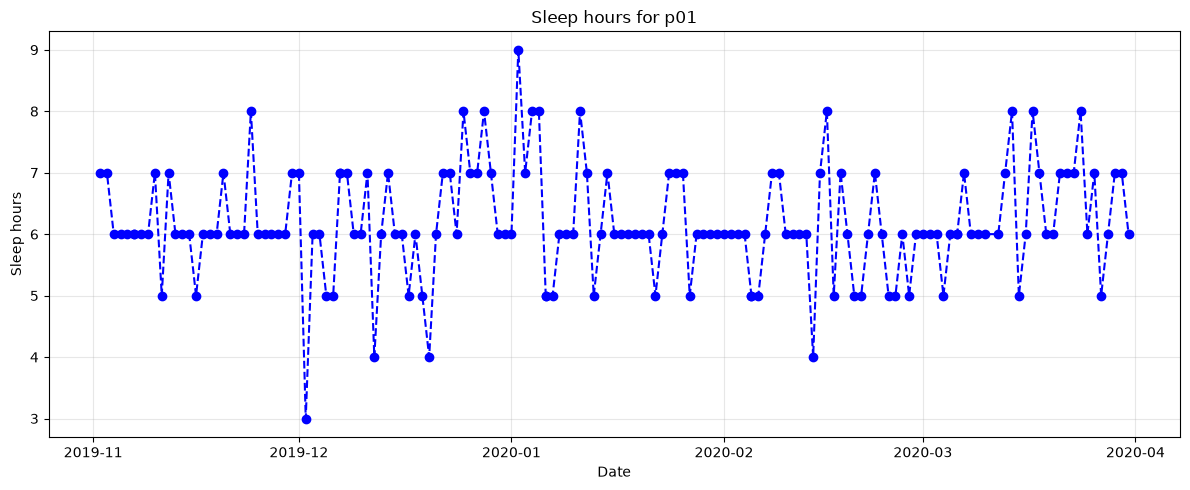

In [27]:
user_id = sleeping['user_id'].unique()[0] 
user_data = sleeping[sleeping['user_id'] == user_id]

plt.figure(figsize=(12, 5))
plt.plot(user_data['dateOfSleep'], user_data['duration[hr]'], color='blue', marker='o', linestyle='--')

plt.title(f'Sleep hours for {user_id}')
plt.xlabel('Date')
plt.ylabel('Sleep hours')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
#Exercises for a person
exercise = []

for folder in os.listdir(main_folder):
    folder_path = os.path.join(main_folder, folder, 'fitbit', 'exercise.json')

    if os.path.exists(folder_path):
            df= pd.read_json(folder_path)
            df['user_id']= folder
            exercise.append(df)


exercise_df = pd.concat(exercise, ignore_index=True)

exercise_df.head()


,logId,activityName,activityTypeId,activityLevel,averageHeartRate,calories,duration,activeDuration,steps,logType,...,source,tcxLink,speed,pace,vo2Max,user_id,swimLengths,poolLength,poolLengthUnit,customHeartRateZones
0,26451905128,Walk,90013,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",94.0,192,1331000,1331000,1878.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
1,26455950499,Walk,90013,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",94.0,302,2202000,2202000,2786.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
2,26467488515,Walk,90013,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",98.0,354,2458000,2458000,3035.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
3,26520401069,Walk,90013,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",97.0,145,1024000,1024000,1284.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
4,26538035127,Walk,90013,"[{'minutes': 3, 'name': 'sedentary'}, {'minute...",93.0,121,973000,973000,1065.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN


In [ ]:
# #What columns do we really need?
#  0   logId                  2440 non-null   int64     -> No
#  1   activityName           2440 non-null   str       -> Yes (Top ~N activites done)
#  2   activityTypeId         2440 non-null   int64     -> No
#  3   activityLevel          2440 non-null   object    -> No
#  4   averageHeartRate       2427 non-null   float64   -> Not as a featue, it’s the mean heart rate over the whole session, which can be a leakage
#  5   calories               2440 non-null   int64     -> No
#  6   duration               2440 non-null   int64     -> Not a feature, but needed to compute the session end
#  7   activeDuration         2440 non-null   int64     -> No (duration - activeDuration = paused time, usable as a quality filter)
#  8   steps                  2271 non-null   float64   -> No (We already have that)
#  9   logType                2440 non-null   str       -> We only take the ones auto_detected or tracker.
#  10  manualValuesSpecified  2440 non-null   object    -> No
#  11  heartRateZones         2425 non-null   object    -> Yes, but only the min/max bpm thresholds, not the minutes
#  12  lastModified           2440 non-null   str       -> No
#  13  startTime              2440 non-null   str       -> Yes (start of the session)
#  14  originalStartTime      2440 non-null   str       -> Filter only (mismatch with startTime = edited log)
#  15  originalDuration       2440 non-null   int64     -> Filter only (mismatch with duration = edited log)
#  16  elevationGain          2282 non-null   float64   -> Not as an input (whole-session total)
#  17  hasGps                 2440 non-null   bool      -> Yes
#  18  shouldFetchDetails     2440 non-null   bool      -> No
#  19  distance               623 non-null    float64   -> Not as an input (whole-session total)
#  20  distanceUnit           623 non-null    str       -> No
#  21  source                 753 non-null    object    -> No
#  22  tcxLink                231 non-null    str       -> No
#  23  speed                  623 non-null    float64   -> Not as an input (session average)
#  24  pace                   344 non-null    float64   -> Not as an input (session average)
#  25  vo2Max                 129 non-null    object    -> Yes
#  26  user_id                2440 non-null   str       -> Yes
#  27  swimLengths            6 non-null      float64   -> Only 6 -> No
#  28  poolLength             6 non-null      float64   -> Only 6 -> No
#  29  poolLengthUnit         6 non-null      str       -> Only 6 -> No
#  30  customHeartRateZones   505 non-null    object    -> No

In [ ]:
exercise_df = exercise_df[~exercise_df['logType'].isin(['manual','mobile_run'])]

exercise_df = exercise_df.drop(columns=['logId', 'activityTypeId', 'activityLevel', 'calories',
                                        'activeDuration', 'steps', 'manualValuesSpecified',
                                        'lastModified', 'shouldFetchDetails', 'distanceUnit',
                                        'source', 'tcxLink', 'swimLengths', 'poolLength',
                                        'poolLengthUnit', 'customHeartRateZones'])
exercise_df['startTime'] = pd.to_datetime(exercise_df['startTime'])
exercise_df.head()


,activityName,averageHeartRate,duration,logType,heartRateZones,startTime,originalStartTime,originalDuration,elevationGain,hasGps,distance,speed,pace,vo2Max,user_id
0,Walk,94.0,1331000,auto_detected,"[{'name': 'Out of Range', 'min': 30, 'max': 86...",2019-11-01 14:56:32,11/01/19 14:56:32,1331000,24.384,False,NaN,NaN,NaN,NaN,p01
1,Walk,94.0,2202000,auto_detected,"[{'name': 'Out of Range', 'min': 30, 'max': 86...",2019-11-01 19:03:11,11/01/19 19:03:11,2202000,27.432,False,NaN,NaN,NaN,NaN,p01
2,Walk,98.0,2458000,auto_detected,"[{'name': 'Out of Range', 'min': 30, 'max': 86...",2019-11-02 13:26:38,11/02/19 13:26:38,2458000,21.336,False,NaN,NaN,NaN,NaN,p01
3,Walk,97.0,1024000,auto_detected,"[{'name': 'Out of Range', 'min': 30, 'max': 86...",2019-11-04 21:22:08,11/04/19 21:22:08,1024000,21.336,False,NaN,NaN,NaN,NaN,p01
4,Walk,93.0,973000,auto_detected,"[{'name': 'Out of Range', 'min': 30, 'max': 86...",2019-11-05 19:27:25,11/05/19 19:27:25,973000,3.048,False,NaN,NaN,NaN,NaN,p01
